# EDA - French Electricity Demand Forecasting

Exploratory Data Analysis for day-ahead electricity demand prediction.

**Objectives:**
1. Load and understand national and regional data
2. Verify if national load = sum of regional loads
3. Identify temporal patterns (hourly, daily, seasonal)
4. Analyze RTE baseline performance
5. Explore feature distributions (temperature, calendar effects)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

# Project root
PROJECT_ROOT = Path('../')
DATA_DIR = PROJECT_ROOT / 'data'

print(f"Data directory: {DATA_DIR}")

Data directory: ../data


## 1. Load National Data

In [2]:
# Load main dataset
df = pd.read_csv(DATA_DIR / 'france_electricity_hourly.csv')

# Convert datetime to proper type
df['datetime_utc'] = pd.to_datetime(df['datetime_utc'])

# Sort by datetime
df = df.sort_values('datetime_utc').reset_index(drop=True)

print(f"National dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nDate range: {df['datetime_utc'].min()} to {df['datetime_utc'].max()}")
print(f"Duration: {(df['datetime_utc'].max() - df['datetime_utc'].min()).days} days")

National dataset shape: (65710, 4)

Columns: ['datetime_utc', 'load_mw', 'rte_forecast_d1_mw', 'temperature_c']

Date range: 2019-01-01 00:00:00+00:00 to 2026-06-30 21:00:00+00:00
Duration: 2737 days


In [3]:
print(f"\nData types:\n{df.dtypes}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nBasic statistics:")
df.describe()


Data types:
datetime_utc          datetime64[ns, UTC]
load_mw                           float64
rte_forecast_d1_mw                float64
temperature_c                     float64
dtype: object

Missing values:
datetime_utc          0
load_mw               7
rte_forecast_d1_mw    7
temperature_c         0
dtype: int64

Basic statistics:


,load_mw,rte_forecast_d1_mw,temperature_c
count,65703.000000,65703.000000,65710.000000
mean,51498.463921,50831.565104,13.071639
std,11018.913253,11048.172035,7.022981
min,29364.000000,27712.000000,-5.090000
25%,43321.500000,42600.000000,7.920000
50%,49768.000000,48962.000000,12.500000
75%,58747.500000,58062.000000,17.980000
max,90210.000000,89975.000000,38.520000


## 2. Load Regional Data

In [4]:
# Load regional dataset (long format: region, datetime, load, temperature)
df_regional = pd.read_csv(DATA_DIR / 'france_regional_electricity_hourly.csv')

# Convert datetime to proper type
df_regional['datetime_utc'] = pd.to_datetime(df_regional['datetime_utc'])

# Convert load_mw and temperature to numeric
df_regional['load_mw'] = pd.to_numeric(df_regional['load_mw'], errors='coerce')
df_regional['temperature_c'] = pd.to_numeric(df_regional['temperature_c'], errors='coerce')

print(f"Regional dataset shape: {df_regional.shape}")
print(f"\nColumns: {df_regional.columns.tolist()}")
print(f"\nFirst few rows:")
print(df_regional.head(10))

Regional dataset shape: (367752, 4)

Columns: ['region', 'datetime_utc', 'load_mw', 'temperature_c']

First few rows:
                 region              datetime_utc  load_mw  temperature_c
0  Auvergne-Rhône-Alpes 2023-01-01 00:00:00+00:00   6028.0           13.3
1  Auvergne-Rhône-Alpes 2023-01-01 01:00:00+00:00   6165.0           13.2
2  Auvergne-Rhône-Alpes 2023-01-01 02:00:00+00:00   6282.0           13.0
3  Auvergne-Rhône-Alpes 2023-01-01 03:00:00+00:00   5779.0           12.8
4  Auvergne-Rhône-Alpes 2023-01-01 04:00:00+00:00   5526.0           12.7
5  Auvergne-Rhône-Alpes 2023-01-01 05:00:00+00:00   5486.0           12.4
6  Auvergne-Rhône-Alpes 2023-01-01 06:00:00+00:00   5554.0           12.3
7  Auvergne-Rhône-Alpes 2023-01-01 07:00:00+00:00   5464.0           12.2
8  Auvergne-Rhône-Alpes 2023-01-01 08:00:00+00:00   5702.0           12.4
9  Auvergne-Rhône-Alpes 2023-01-01 09:00:00+00:00   5853.0           13.5


In [5]:
# Explore regions
regions = sorted(df_regional['region'].unique())
print(f"Number of regions: {len(regions)}")
print(f"\nRegions: {regions}")

Number of regions: 12

Regions: ['Auvergne-Rhône-Alpes', 'Bourgogne-Franche-Comté', 'Bretagne', 'Centre-Val de Loire', 'Grand Est', 'Hauts-de-France', 'Normandie', 'Nouvelle-Aquitaine', 'Occitanie', 'Pays de la Loire', "Provence-Alpes-Côte d'Azur", 'Île-de-France']


## 3. Compare National vs Regional Aggregation

In [6]:
# Aggregate regional loads by datetime (sum across all regions)
regional_total = df_regional.groupby('datetime_utc')['load_mw'].sum().reset_index()
regional_total.rename(columns={'load_mw': 'total_regional_load'}, inplace=True)

# Merge with national data
comparison = df[['datetime_utc', 'load_mw']].copy()
comparison = comparison.merge(regional_total, on='datetime_utc', how='inner')

comparison['difference'] = comparison['load_mw'] - comparison['total_regional_load']

print(f"National vs Regional aggregation:")
print(f"Mean difference: {comparison['difference'].mean():.2f} MW")
print(f"Std difference: {comparison['difference'].std():.2f} MW")
print(f"Max absolute difference: {comparison['difference'].abs().max():.2f} MW")
print(f"\nCorrelation: {comparison['load_mw'].corr(comparison['total_regional_load']):.4f}")

National vs Regional aggregation:
Mean difference: -0.04 MW
Std difference: 9.37 MW
Max absolute difference: 1620.00 MW

Correlation: 1.0000


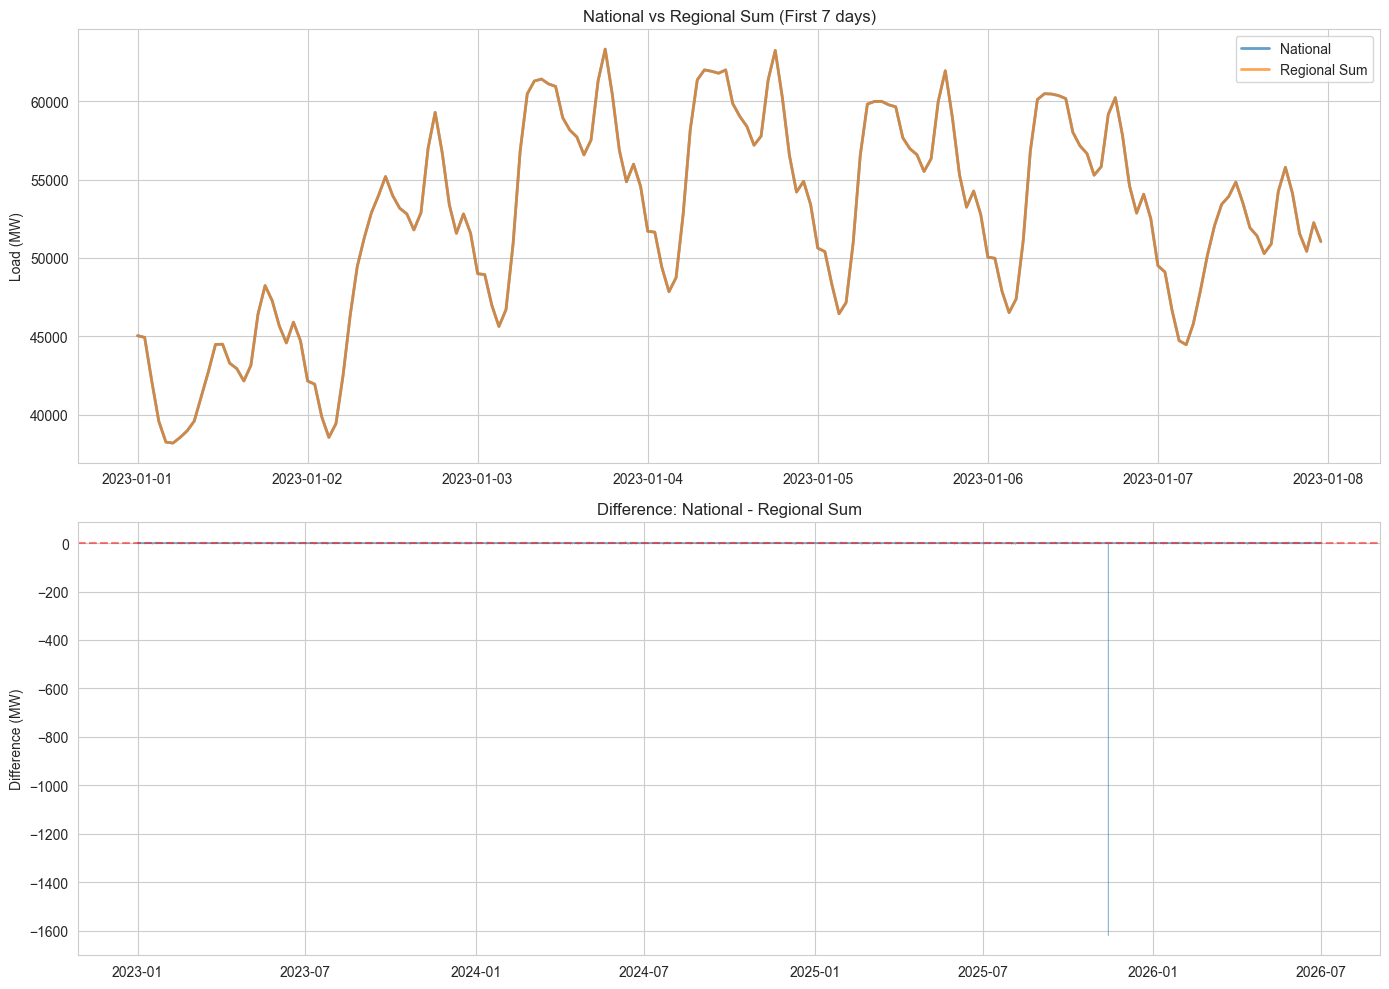

In [7]:
# Plot comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# First 7 days comparison
mask = comparison['datetime_utc'] < comparison['datetime_utc'].min() + pd.Timedelta(days=7)
axes[0].plot(comparison.loc[mask, 'datetime_utc'], comparison.loc[mask, 'load_mw'], 
            label='National', alpha=0.7, linewidth=2)
axes[0].plot(comparison.loc[mask, 'datetime_utc'], comparison.loc[mask, 'total_regional_load'], 
            label='Regional Sum', alpha=0.7, linewidth=2)
axes[0].set_title('National vs Regional Sum (First 7 days)')
axes[0].set_ylabel('Load (MW)')
axes[0].legend()
axes[0].grid(True)

# Difference over time
axes[1].plot(comparison['datetime_utc'], comparison['difference'], alpha=0.5, linewidth=0.5)
axes[1].axhline(y=0, color='r', linestyle='--', alpha=0.5)
axes[1].set_title('Difference: National - Regional Sum')
axes[1].set_ylabel('Difference (MW)')
axes[1].grid(True)

plt.tight_layout()
plt.show()